In [4]:
!pip install numpy pandas matplotlib seaborn scikit-learn

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

print("First 5 rows:")
display(df.head())

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

numerical_columns = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "time"
]

before_stats = df[numerical_columns].agg(["mean", "median", "std"])

print("\nStatistics Before Cleaning:")
display(before_stats)

First 5 rows:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Number of rows: 299
Number of columns: 13

Data Types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing Values:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Dataset Information:
<class 'pandas.core.

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time
mean,60.833893,581.839465,38.083612,263358.029264,1.39388,136.625418,130.260870
median,60.000000,250.000000,38.000000,262000.000000,1.10000,137.000000,115.000000
std,11.894809,970.287881,11.834841,97804.236869,1.03451,4.412477,77.614208


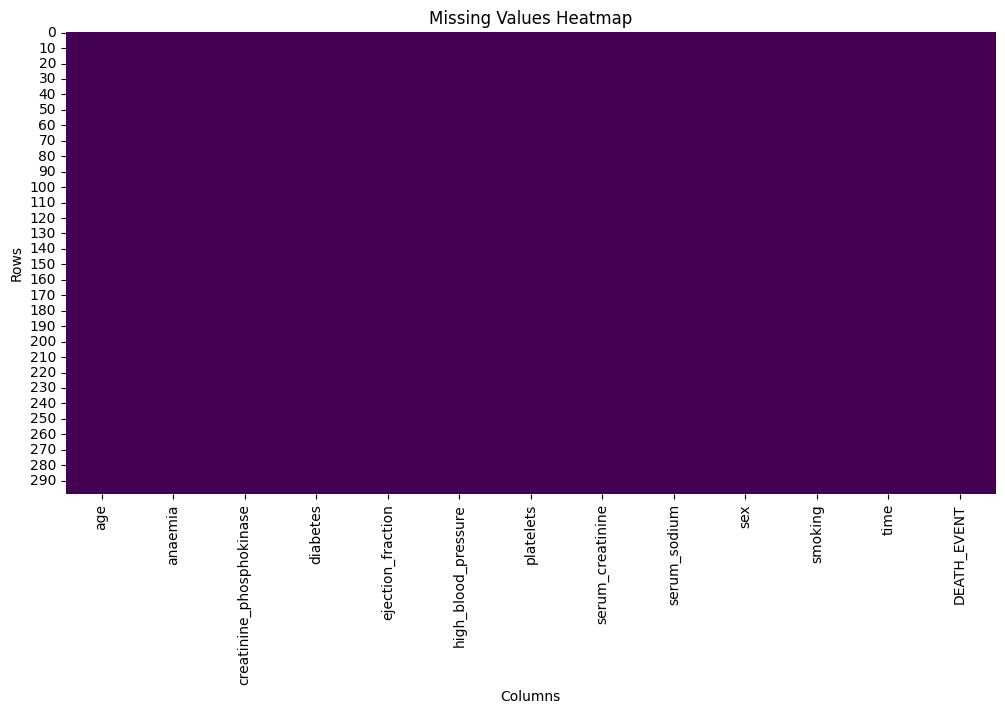

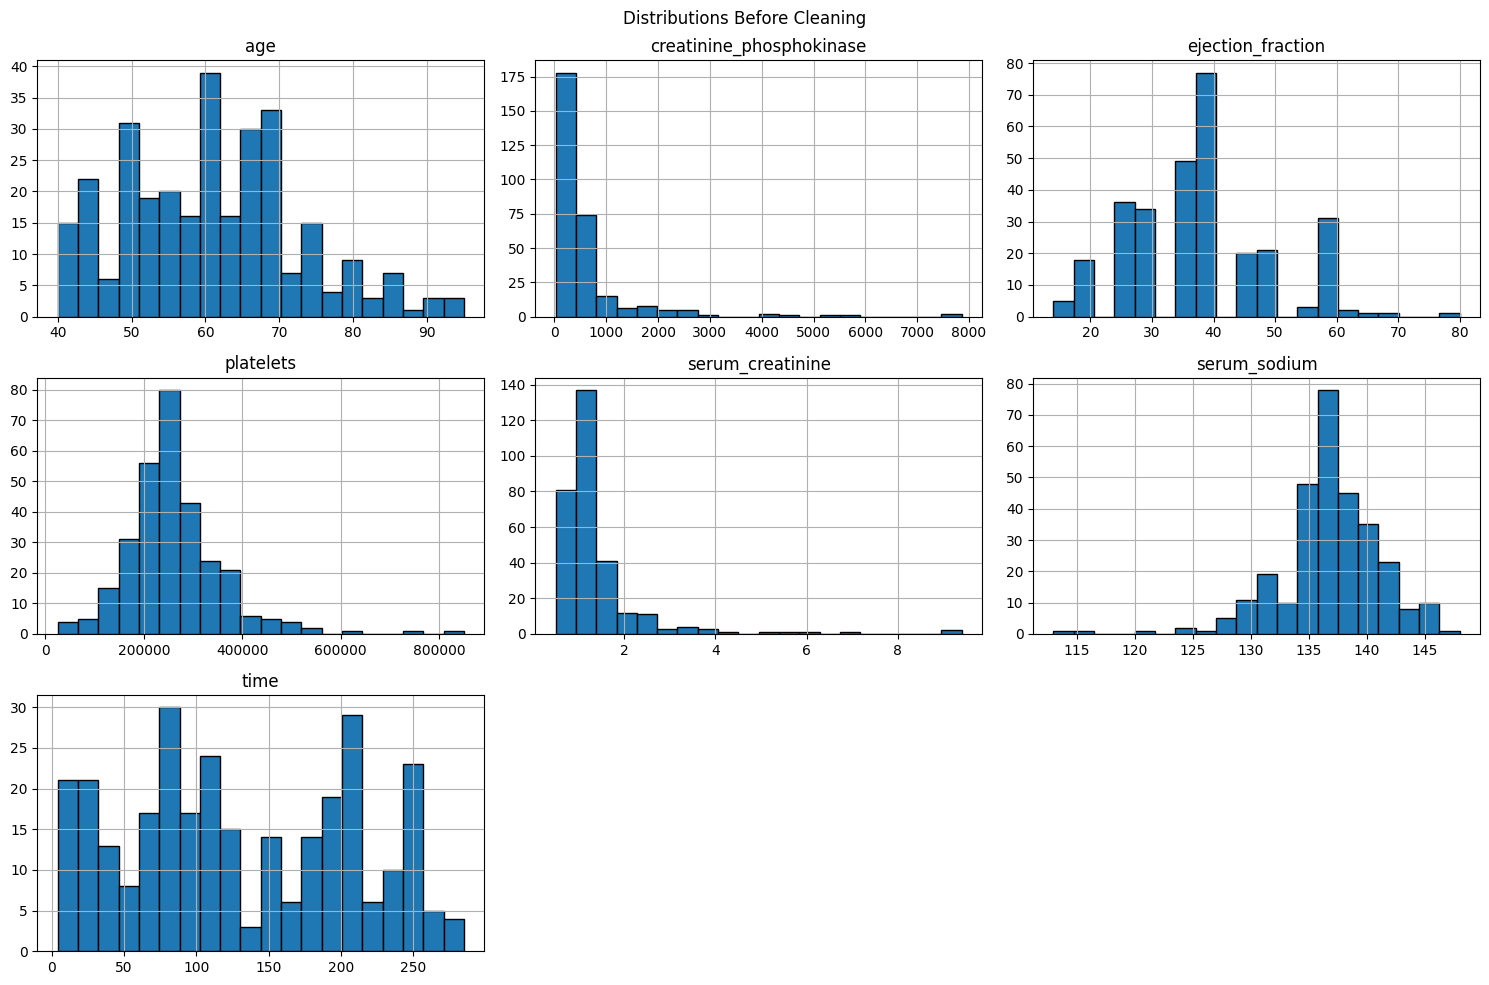

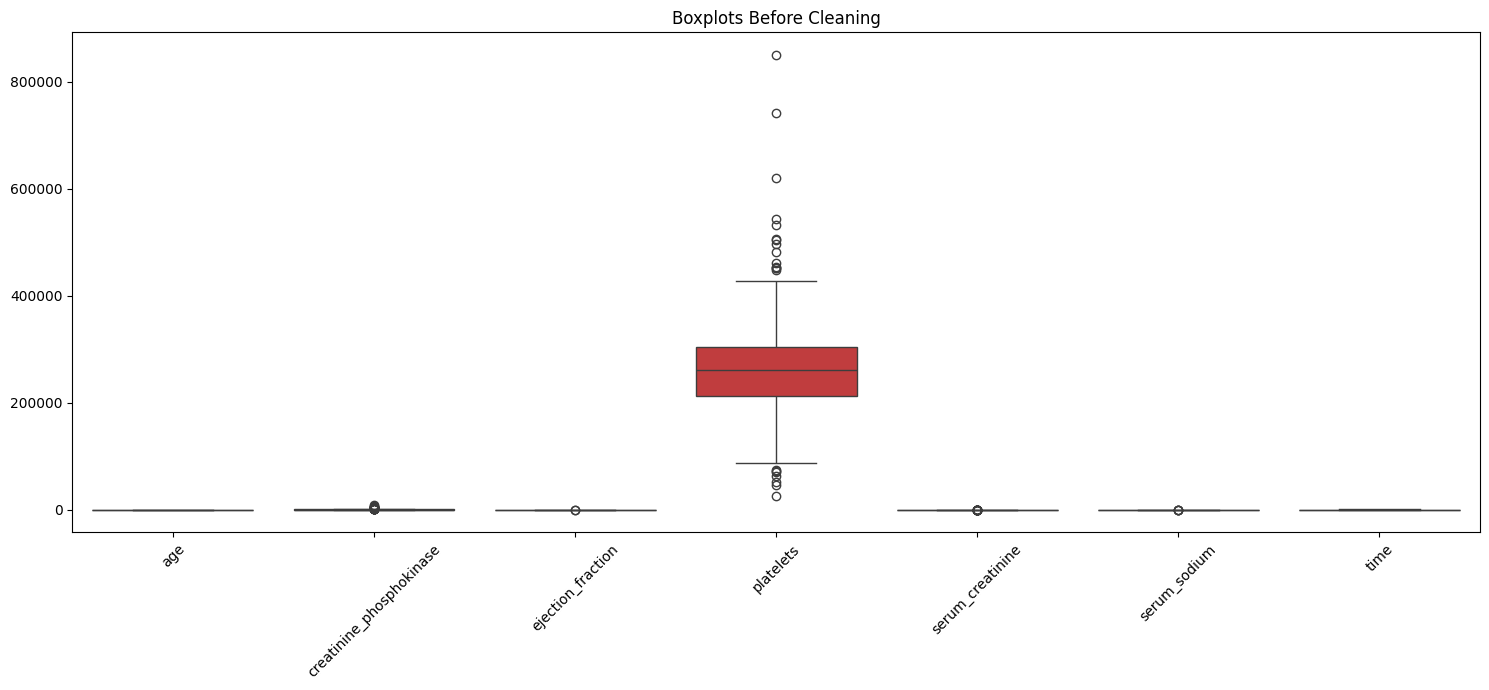

In [12]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

df[numerical_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distributions Before Cleaning")
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 7))
sns.boxplot(data=df[numerical_columns])
plt.title("Boxplots Before Cleaning")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
categorical_columns = [
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking",
    "DEATH_EVENT"
]

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

df["age"] = df["age"].abs()
df["ejection_fraction"] = df["ejection_fraction"].clip(0, 100)
df["serum_creatinine"] = df["serum_creatinine"].clip(lower=0)
df["serum_sodium"] = df["serum_sodium"].clip(lower=0)
df["platelets"] = df["platelets"].clip(lower=0)
df["creatinine_phosphokinase"] = df["creatinine_phosphokinase"].clip(lower=0)

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
).any(axis=1)

print("Number of outlier rows:", outlier_mask.sum())

df = df[~outlier_mask].reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("\nMissing values after imputation:")
print(df.isnull().sum())

Number of outlier rows: 75
Dataset shape after cleaning: (224, 13)

Missing values after imputation:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


In [14]:
def create_age_group(age):
    if age < 40:
        return "<40"
    elif age <= 60:
        return "40-60"
    else:
        return ">60"

df["age_group"] = df["age"].apply(create_age_group)

df["risk_score"] = (
    df["ejection_fraction"] * df["serum_creatinine"]
)

risk_min = df["risk_score"].min()
risk_max = df["risk_score"].max()

if risk_max != risk_min:
    df["risk_score"] = (
        (df["risk_score"] - risk_min) /
        (risk_max - risk_min)
    )
else:
    df["risk_score"] = 0

categorical_features = [
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking",
    "age_group"
]

df = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Feature engineering and categorical encoding completed.")
display(df.head())

Feature engineering and categorical encoding completed.


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_score,anaemia_1,diabetes_1,high_blood_pressure_1,sex_1,smoking_1,age_group_>60
0,75.0,582,20,265000.0,1.9,130,4,1,0.310545,0,0,1,1,0,1
1,65.0,146,20,162000.0,1.3,129,7,1,0.171495,0,0,0,1,1,1
2,50.0,111,20,210000.0,1.9,137,7,1,0.310545,1,0,0,1,0,0
3,90.0,47,40,204000.0,2.1,132,8,1,0.843569,1,0,1,1,1,1
4,75.0,246,15,127000.0,1.2,137,10,1,0.078795,1,0,0,1,0,1


In [15]:
scale_columns = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "time"
]

scaler = MinMaxScaler()

df[scale_columns] = scaler.fit_transform(df[scale_columns])

after_stats = df[scale_columns].agg(["mean", "median", "std"])

print("Mean, Median and Standard Deviation Before Cleaning:")
display(before_stats)

print("\nMean, Median and Standard Deviation After Cleaning:")
display(after_stats)

Mean, Median and Standard Deviation Before Cleaning:


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time
mean,60.833893,581.839465,38.083612,263358.029264,1.39388,136.625418,130.260870
median,60.000000,250.000000,38.000000,262000.000000,1.10000,137.000000,115.000000
std,11.894809,970.287881,11.834841,97804.236869,1.03451,4.412477,77.614208



Mean, Median and Standard Deviation After Cleaning:


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time
mean,0.378355,0.261896,0.474090,0.438902,0.352381,0.523680,0.457836
median,0.363636,0.155290,0.470588,0.460656,0.333333,0.521739,0.412811
std,0.217202,0.238499,0.229624,0.220176,0.218530,0.165510,0.272526


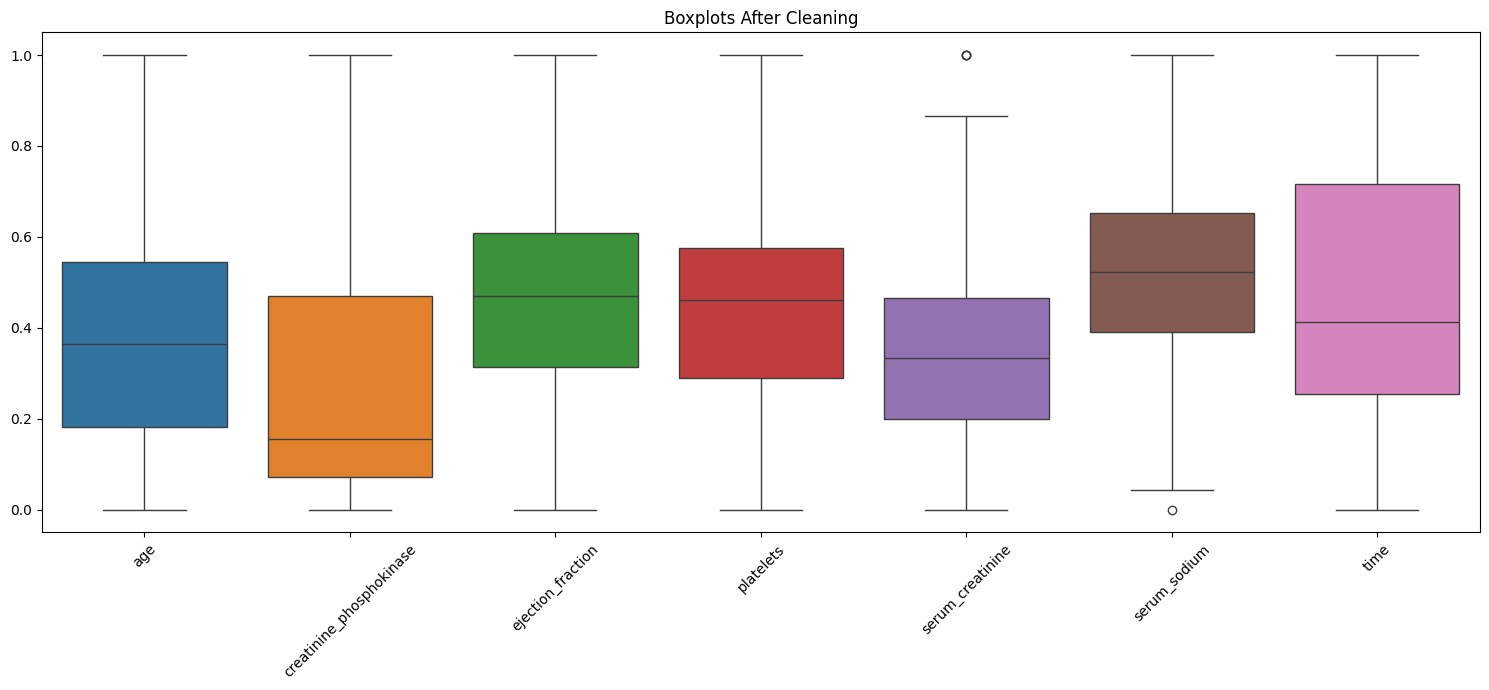

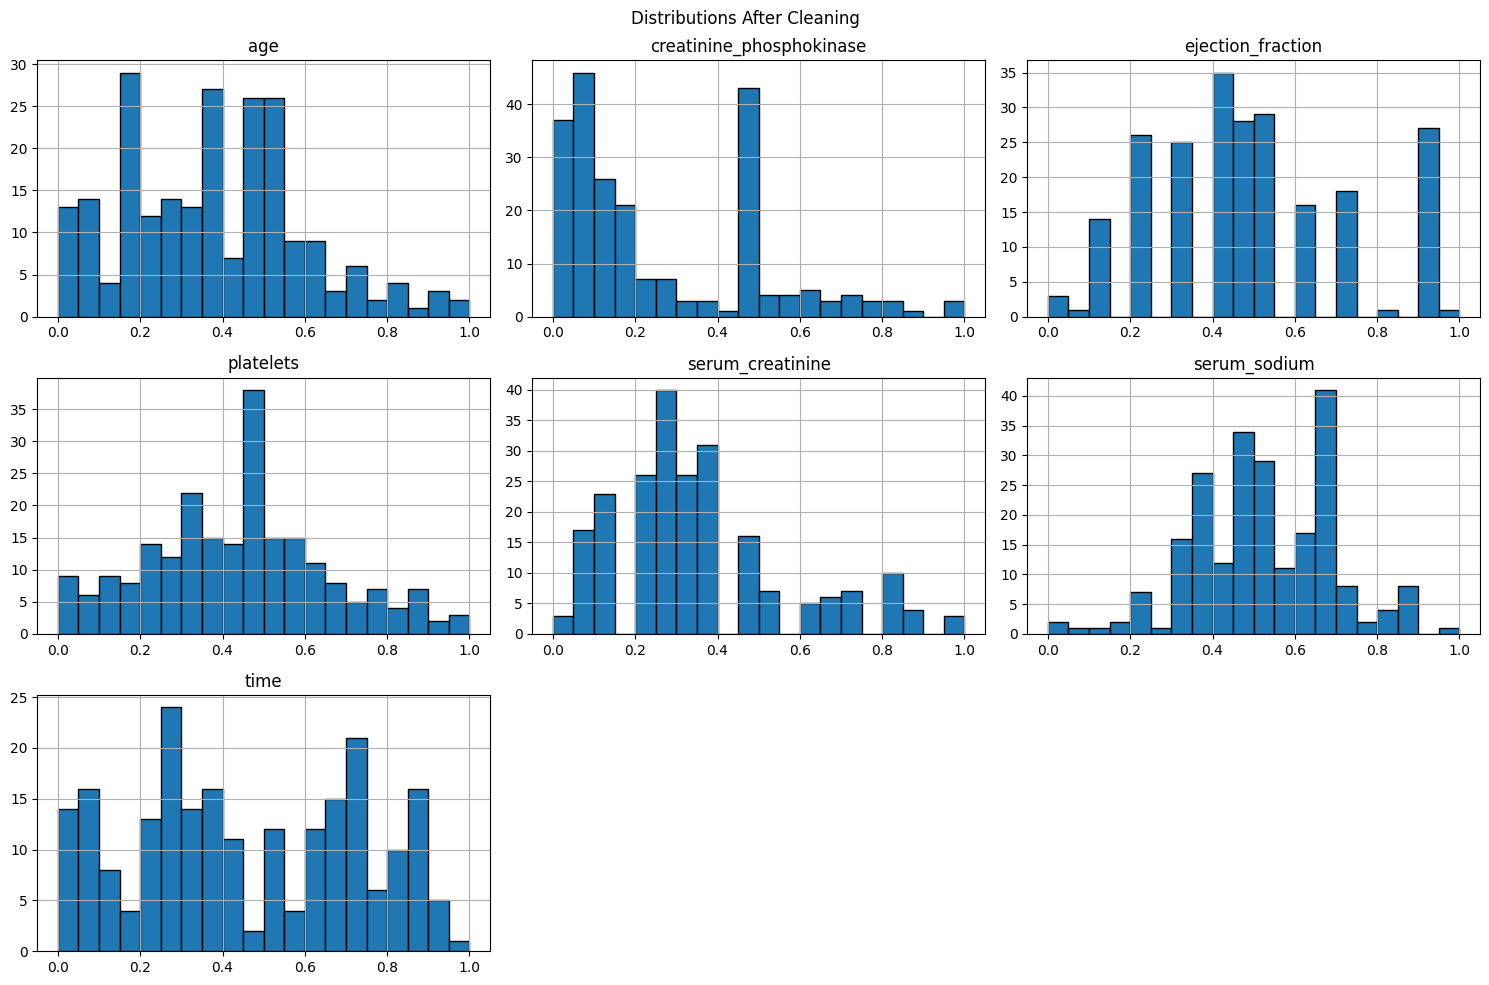

Missing values after cleaning:
age                         0
creatinine_phosphokinase    0
ejection_fraction           0
platelets                   0
serum_creatinine            0
serum_sodium                0
time                        0
DEATH_EVENT                 0
risk_score                  0
anaemia_1                   0
diabetes_1                  0
high_blood_pressure_1       0
sex_1                       0
smoking_1                   0
age_group_>60               0
dtype: int64

Total missing values: 0

Final Dataset Shape: (224, 15)


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_score,anaemia_1,diabetes_1,high_blood_pressure_1,sex_1,smoking_1,age_group_>60
0,0.636364,0.470990,0.117647,0.468852,0.866667,0.217391,0.000000,1,0.310545,0,0,1,1,0,1
1,0.454545,0.098976,0.117647,0.131148,0.466667,0.173913,0.010676,1,0.171495,0,0,0,1,1,1
2,0.181818,0.069113,0.117647,0.288525,0.866667,0.521739,0.010676,1,0.310545,1,0,0,1,0,0
3,0.909091,0.014505,0.509804,0.268852,1.000000,0.304348,0.014235,1,0.843569,1,0,1,1,1,1
4,0.636364,0.184300,0.019608,0.016393,0.400000,0.521739,0.021352,1,0.078795,1,0,0,1,0,1



Cleaned CSV and Excel files saved successfully.


In [16]:
plt.figure(figsize=(15, 7))
sns.boxplot(data=df[scale_columns])
plt.title("Boxplots After Cleaning")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df[scale_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distributions After Cleaning")
plt.tight_layout()
plt.show()

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nFinal Dataset Shape:", df.shape)

display(df.head())

df.to_csv("cleaned_heart_failure_dataset.csv", index=False)
df.to_excel("cleaned_heart_failure_dataset.xlsx", index=False)

print("\nCleaned CSV and Excel files saved successfully.")